# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Mahardika Indra Pratama Ilyasa | 5054251045 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [24]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics

import kagglehub
from kagglehub import KaggleDatasetAdapter
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score


In [25]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.

path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
print("Dataset berhasil diunduh dari: ", path)
files = os.listdir(path)
csv_filename = [f for f in files if f.endswith('.csv')][0]
csv_path = os.path.join(path, csv_filename)
df = pd.read_csv(csv_path)
print("First 5 records:", df.head())
print("Number of rows and columns:", df.shape)
print("Data types:", df.dtypes)
print("Descriptive statistics:", df.describe())
print("Missing values:", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
Dataset berhasil diunduh dari:  /kaggle/input/customer-segmentation-tutorial-in-python
First 5 records:    CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Number of rows and columns: (200, 5)
Data types: CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object
Descriptive statistics:        CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000

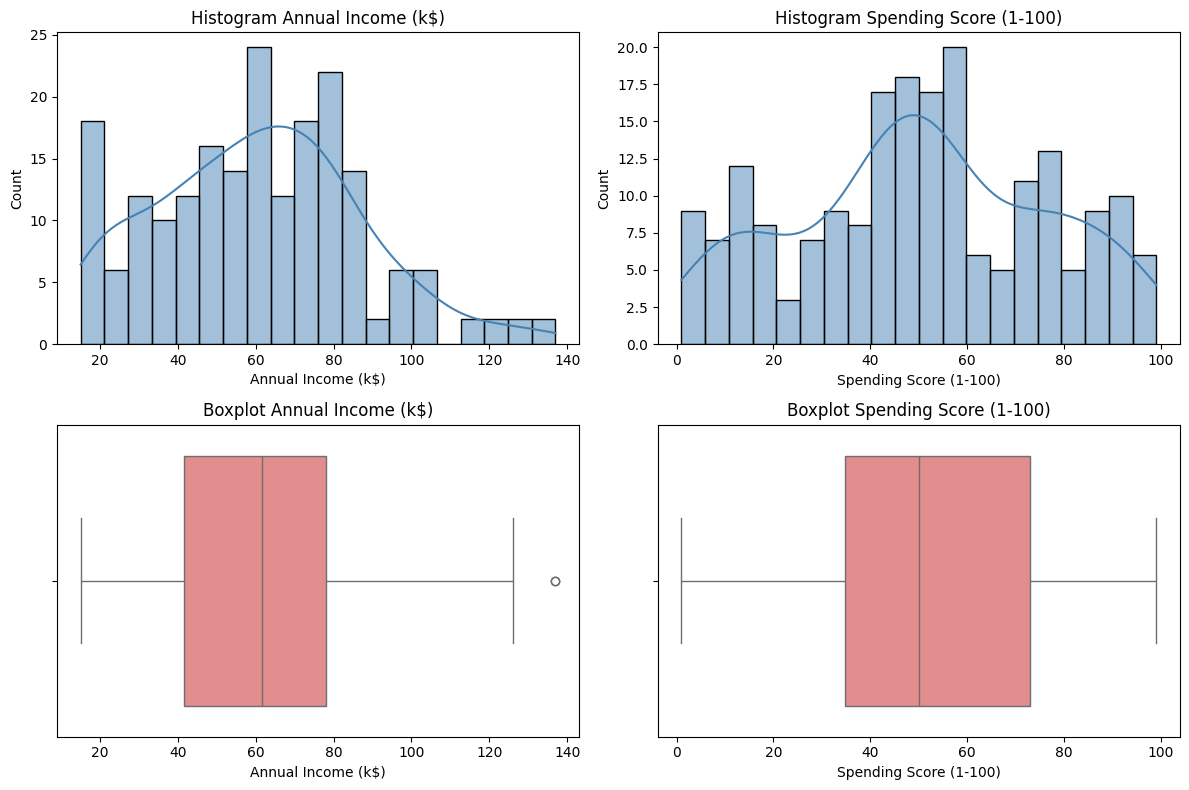

Annual Income (k$): min=15, max=137, skewness=0.322, jumlah outlier (IQR)=2
Spending Score (1-100): min=1, max=99, skewness=-0.047, jumlah outlier (IQR)=0


In [26]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.

fitur = ['Annual Income (k$)', 'Spending Score (1-100)']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, kolom in enumerate(fitur):
    sns.histplot(df[kolom], bins=20, kde=True, ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'Histogram {kolom}')
    sns.boxplot(x=df[kolom], ax=axes[1, i], color='lightcoral')
    axes[1, i].set_title(f'Boxplot {kolom}')
plt.tight_layout()
plt.show()

# Ringkasan rentang dan deteksi outlier dengan aturan IQR
for kolom in fitur:
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier = df[(df[kolom] < batas_bawah) | (df[kolom] > batas_atas)]
    print(f"{kolom}: min={df[kolom].min()}, max={df[kolom].max()}, "
          f"skewness={df[kolom].skew():.3f}, jumlah outlier (IQR)={len(outlier)}")

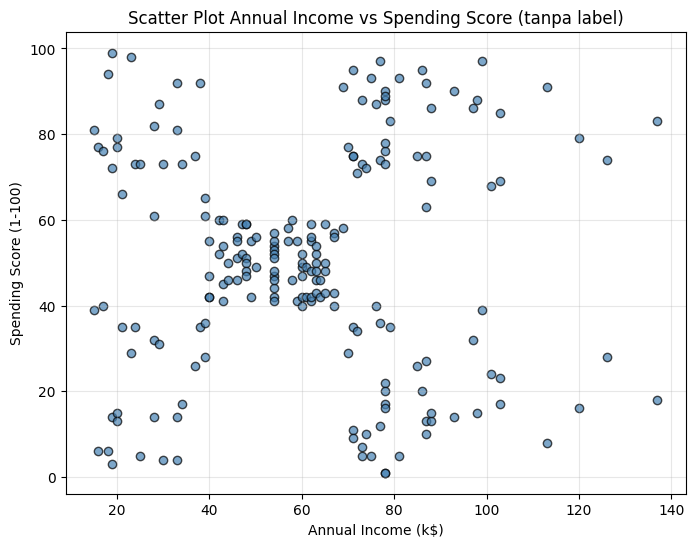

In [27]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.

plt.figure(figsize=(8, 6))
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'],
            color='steelblue', edgecolor='k', alpha=0.7)
plt.title('Scatter Plot Annual Income vs Spending Score (tanpa label)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(alpha=0.3)
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

### Jawaban

**1. Missing value dan baris duplikat.**
Berdasarkan output `df.isnull().sum()` dan `df.duplicated().sum()`, **tidak ada missing value** pada kelima kolom (`CustomerID`, `Gender`, `Age`, `Annual Income (k$)`, `Spending Score (1-100)`) dan **tidak ada baris duplikat** (jumlah duplikat = 0). Dataset berisi 200 baris dan 5 kolom, sehingga data sudah bersih dan tidak perlu imputasi atau penghapusan baris. Tipe data kedua fitur yang dipakai adalah `int64`, jadi langsung dapat diproses tanpa konversi.

**2. Rentang pendapatan dan spending score.**
- `Annual Income (k$)`: minimum 15, maksimum 137, rata-rata 60,56, median 61,5, standar deviasi 26,26. Separuh pelanggan berada pada rentang 41,5 sampai 78 (Q1 sampai Q3). Dengan aturan IQR (IQR = 36,5; batas atas = 78 + 1,5 x 36,5 = 132,75), nilai 137 sedikit melewati batas atas sehingga ada sedikit titik yang secara statistik tergolong outlier ringan. Titik tersebut berupa pelanggan berpendapatan sangat tinggi, bukan kesalahan data, sehingga tidak dihapus.
- `Spending Score (1-100)`: minimum 1, maksimum 99, rata-rata 50,2, median 50, standar deviasi 25,82. Rata-rata hampir sama dengan median sehingga distribusinya cukup simetris, dan seluruh nilai berada di dalam batas IQR (-22,6 sampai 130,4) sehingga tidak ada outlier.
- Kedua fitur memiliki skala yang kurang lebih sebanding (sama-sama dengan standar deviasi sekitar 26), tetapi tetap perlu di-scaling agar rata-rata 0 dan standar deviasi 1 untuk algoritma berbasis jarak.

**3. Apakah ada kelompok yang terpisah?**
Ya. Pada scatter plot, titik-titik tidak tersebar acak, melainkan membentuk beberapa kelompok yang cukup jelas, dengan pola yang paling terlihat sekitar **lima kelompok**: (a) pendapatan rendah dengan spending rendah, (b) pendapatan rendah dengan spending tinggi, (c) kelompok besar di tengah (pendapatan dan spending sedang), (d) pendapatan tinggi dengan spending rendah, dan (e) pendapatan tinggi dengan spending tinggi. Kelompok tengah paling padat, sedangkan keempat kelompok di sudut lebih kecil. Karena adanya pola ini, dataset cocok untuk eksperimen clustering.

# 2. Preprocessing

In [28]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.

# Periksa missing value dan duplikat
print("Missing value per kolom:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

# Tangani jika ditemukan (pada dataset ini seharusnya tidak ada)
if df.isnull().sum().sum() > 0:
    df = df.dropna().reset_index(drop=True)
    print("Baris dengan missing value telah dihapus.")
if df.duplicated().sum() > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Baris duplikat telah dihapus.")

# Pilih dua fitur numerik (CustomerID dan Gender tidak dimasukkan)
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()
print("\nBentuk X:", X.shape)
X.head()

Missing value per kolom:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah baris duplikat: 0

Bentuk X: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [29]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.

scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns, index=X.index)

print("Beberapa baris X_scaled:")
display(X_scaled.head())
print("\nStatistik deskriptif X_scaled:")
display(X_scaled.describe().round(4))

Beberapa baris X_scaled:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Statistik deskriptif X_scaled:


,Annual Income (k$),Spending Score (1-100)
count,200.0000,200.0000
mean,-0.0000,-0.0000
std,1.0025,1.0025
min,-1.7390,-1.9100
25%,-0.7275,-0.5998
50%,0.0359,-0.0078
75%,0.6657,0.8851
max,2.9177,1.8945


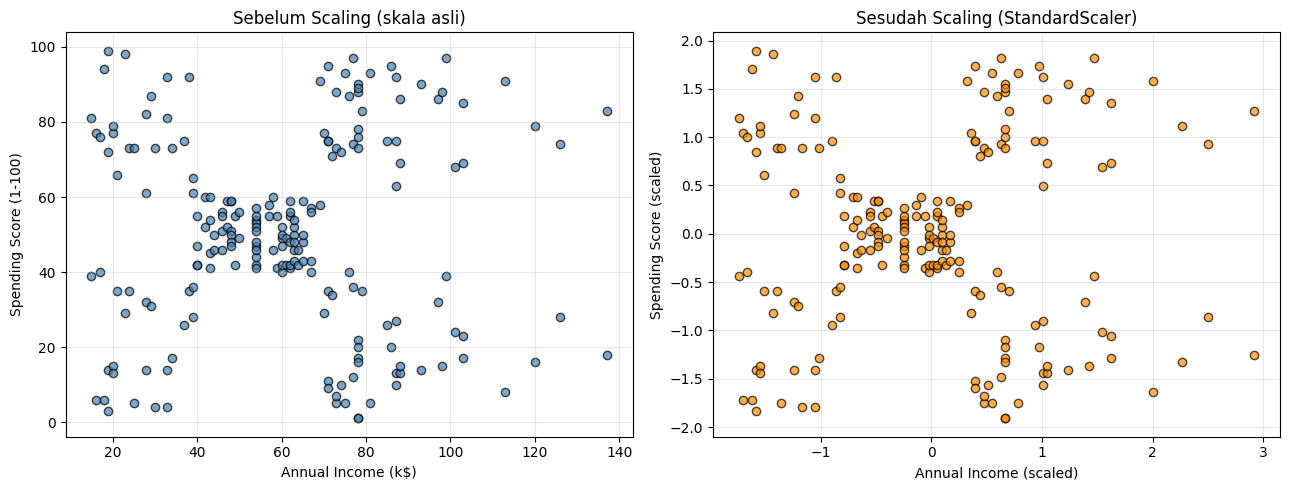

Rentang sebelum scaling : {'Annual Income (k$)': 122, 'Spending Score (1-100)': 98}
Rentang sesudah scaling : {'Annual Income (k$)': 4.657, 'Spending Score (1-100)': 3.805}
Std sebelum scaling     : {'Annual Income (k$)': 26.265, 'Spending Score (1-100)': 25.824}
Std sesudah scaling     : {'Annual Income (k$)': 1.003, 'Spending Score (1-100)': 1.003}


In [30]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], color='steelblue', edgecolor='k', alpha=0.7)
axes[0].set_title('Sebelum Scaling (skala asli)')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[0].grid(alpha=0.3)

axes[1].scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], color='darkorange', edgecolor='k', alpha=0.7)
axes[1].set_title('Sesudah Scaling (StandardScaler)')
axes[1].set_xlabel('Annual Income (scaled)')
axes[1].set_ylabel('Spending Score (scaled)')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Perbandingan rentang dan standar deviasi sebelum dan sesudah scaling
print("Rentang sebelum scaling :", (X.max() - X.min()).to_dict())
print("Rentang sesudah scaling :", (X_scaled.max() - X_scaled.min()).round(3).to_dict())
print("Std sebelum scaling     :", X.std().round(3).to_dict())
print("Std sesudah scaling     :", X_scaled.std().round(3).to_dict())

# Scaling penting karena DBSCAN (eps), BIRCH (threshold), dan GMM (kovarians) sangat
# bergantung pada jarak/skala fitur. Fitur dengan rentang lebih besar akan mendominasi
# perhitungan jarak jika tidak di-scaling, dan parameter seperti eps menjadi sulit
# ditafsirkan karena satuannya berbeda untuk setiap fitur.

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

### Jawaban

**Alasan memilih `Annual Income (k$)` dan `Spending Score (1-100)`:**
1. Kedua fitur ini langsung menggambarkan dimensi bisnis yang relevan untuk segmentasi pelanggan: kemampuan finansial (pendapatan) dan perilaku belanja (spending score).
2. Dengan dua fitur numerik, hasil clustering dapat divisualisasikan langsung pada bidang 2D sehingga kualitas cluster bisa dinilai secara visual, bukan hanya lewat angka metrik.
3. Pada EDA terlihat bahwa kedua fitur ini membentuk kelompok yang cukup jelas, sehingga cocok sebagai dasar perbandingan DBSCAN, BIRCH, dan GMM. Kolom `Age` dan `Gender` tidak dipakai sebagai input agar fokus tetap pada dua fitur dan sesuai ketentuan tugas, tetapi boleh dipakai untuk interpretasi setelah model selesai.

**Alasan `CustomerID` tidak digunakan:**
`CustomerID` hanyalah nomor identitas/urutan (1 sampai 200) yang tidak membawa informasi tentang perilaku atau karakteristik pelanggan. Jika dimasukkan, nilainya akan ikut menghitung jarak antar titik.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [31]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)
print("Label unik DBSCAN:", np.unique(labels_dbscan))

Label unik DBSCAN: [-1  0  1  2  3  4  5  6]


In [32]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).

jumlah_per_label = pd.Series(labels_dbscan).value_counts().sort_index()
print("Jumlah anggota tiap label DBSCAN (label -1 = noise):")
print(jumlah_per_label)

n_cluster_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_dbscan = int(np.sum(labels_dbscan == -1))
print(f"\nJumlah cluster (tanpa noise): {n_cluster_dbscan}")
print(f"Jumlah titik noise          : {n_noise_dbscan} ({n_noise_dbscan / len(labels_dbscan):.1%})")

Jumlah anggota tiap label DBSCAN (label -1 = noise):
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

Jumlah cluster (tanpa noise): 7
Jumlah titik noise          : 35 (17.5%)


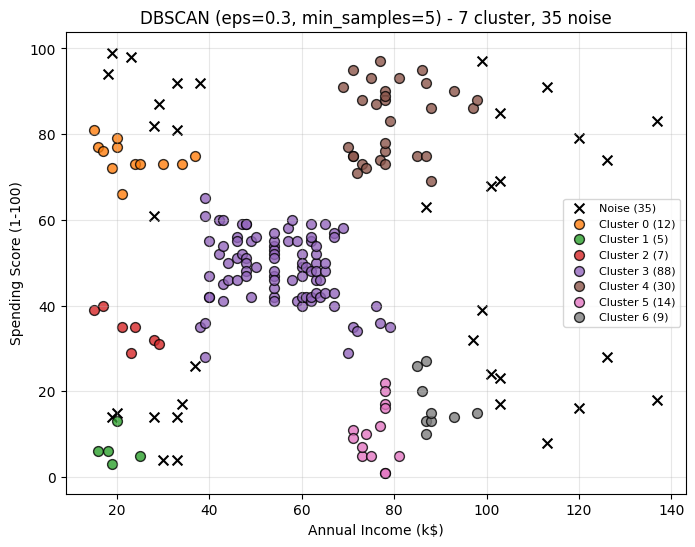

In [33]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.

def plot_clusters(ax, data, labels, title, noise_label=-1):
    """Scatter plot cluster; titik noise (label -1) digambar sebagai 'x' hitam."""
    unik = sorted(set(labels))
    cmap = plt.get_cmap('tab10')
    for k, lab in enumerate(unik):
        mask = labels == lab
        if lab == noise_label:
            ax.scatter(data.iloc[mask, 0], data.iloc[mask, 1], c='black', marker='x',
                       s=50, label=f'Noise ({mask.sum()})')
        else:
            ax.scatter(data.iloc[mask, 0], data.iloc[mask, 1], color=cmap(k % 10),
                       edgecolor='k', alpha=0.8, s=50, label=f'Cluster {lab} ({mask.sum()})')
    ax.set_title(title)
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score (1-100)')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig, ax = plt.subplots(figsize=(8, 6))
plot_clusters(ax, X, labels_dbscan,
              f'DBSCAN (eps=0.3, min_samples=5) - {n_cluster_dbscan} cluster, {n_noise_dbscan} noise')
plt.show()

,eps,min_samples,n_cluster,n_noise,noise_%,silhouette
0,0.2,3,13,44,22.0,0.4697
1,0.2,5,7,77,38.5,0.5856
2,0.2,7,4,100,50.0,0.6094
3,0.2,10,1,129,64.5,NaN
4,0.3,3,9,14,7.0,0.4720
5,0.3,5,7,35,17.5,0.5243
6,0.3,7,4,72,36.0,0.6452
7,0.3,10,4,88,44.0,0.6073
8,0.4,3,4,10,5.0,0.3954
9,0.4,5,4,15,7.5,0.4781


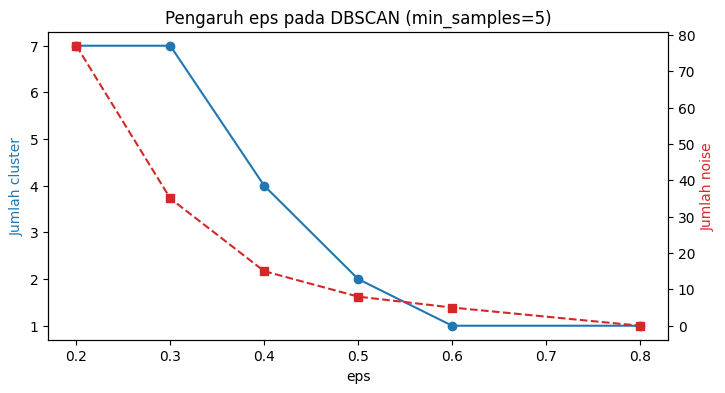

In [34]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.

hasil_dbscan = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6, 0.8]:
    for ms in [3, 5, 7, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        n_ns = int(np.sum(lab == -1))
        mask = lab != -1
        # Silhouette hanya dihitung pada titik non-noise dan bila ada >= 2 cluster
        if n_cl >= 2 and mask.sum() > n_cl:
            sil = silhouette_score(X_scaled[mask], lab[mask])
        else:
            sil = np.nan
        hasil_dbscan.append({'eps': eps, 'min_samples': ms, 'n_cluster': n_cl,
                             'n_noise': n_ns, 'noise_%': round(100 * n_ns / len(lab), 1),
                             'silhouette': sil})

df_dbscan_grid = pd.DataFrame(hasil_dbscan)
display(df_dbscan_grid.round(4))

sub = df_dbscan_grid[df_dbscan_grid['min_samples'] == 5]
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(sub['eps'], sub['n_cluster'], 'o-', color='tab:blue', label='Jumlah cluster')
ax1.set_xlabel('eps'); ax1.set_ylabel('Jumlah cluster', color='tab:blue')
ax2 = ax1.twinx()
ax2.plot(sub['eps'], sub['n_noise'], 's--', color='tab:red', label='Jumlah noise')
ax2.set_ylabel('Jumlah noise', color='tab:red')
plt.title('Pengaruh eps pada DBSCAN (min_samples=5)')
plt.show()

### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

### Jawaban

**1. Pengaruh kenaikan `eps`.**
`eps` adalah radius ketetanggaan. Ketika `eps` dinaikkan, lebih banyak titik masuk ke ketetanggaan titik lain sehingga:
- **Jumlah noise menurun**, karena semakin banyak titik yang akhirnya terjangkau dari suatu titik inti (kolom `n_noise` dan `noise_%` pada tabel `df_dbscan_grid` turun seiring `eps` membesar).
- **Jumlah cluster** mula-mula dapat bertambah/stabil ketika cluster yang sebelumnya terfragmentasi atau seluruhnya noise mulai terbentuk, lalu **menurun** ketika cluster yang berdekatan saling tersambung (*chaining*) dan menyatu menjadi cluster yang lebih besar. Pada `eps` yang cukup besar hasilnya hanya tersisa satu atau sedikit cluster, dan Silhouette tidak dapat dihitung (`NaN`) bila hanya ada satu cluster.
- Sebaliknya, `eps` yang terlalu kecil (misalnya 0,2) membuat banyak titik tidak memenuhi syarat kepadatan sehingga cluster terpecah-pecah dan proporsi noise tinggi.

**2. Pengaruh `min_samples`.**
`min_samples` menentukan seberapa padat suatu titik agar menjadi *core point*. Semakin besar nilainya, syarat kepadatan makin ketat sehingga **noise bertambah**, titik di tepi cluster dan area yang renggang berubah menjadi noise, dan cluster kecil dapat hilang seluruhnya.

**3. Kombinasi yang bermasalah.**
Ya, ada dua pola ekstrem pada tabel:
- `eps` kecil + `min_samples` besar menghasilkan **terlalu banyak noise** (sebagian besar titik tidak terklasifikasi) dan hanya menyisakan inti cluster terpadat.
- `eps` besar + `min_samples` kecil menghasilkan **satu cluster besar** (atau sedikit cluster) karena seluruh kelompok tersambung, sehingga tidak ada pemisahan segmen.


# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [35]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.

birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)
print("Label unik BIRCH:", np.unique(labels_birch))
print("Jumlah subcluster (leaf) yang terbentuk di pohon CF:", len(birch.subcluster_centers_))

Label unik BIRCH: [0 1 2 3 4]
Jumlah subcluster (leaf) yang terbentuk di pohon CF: 10


In [36]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.

print("Jumlah anggota tiap cluster BIRCH:")
print(pd.Series(labels_birch).value_counts().sort_index())
n_cluster_birch = len(np.unique(labels_birch))
print("\nJumlah cluster yang terbentuk:", n_cluster_birch)

Jumlah anggota tiap cluster BIRCH:
0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64

Jumlah cluster yang terbentuk: 5


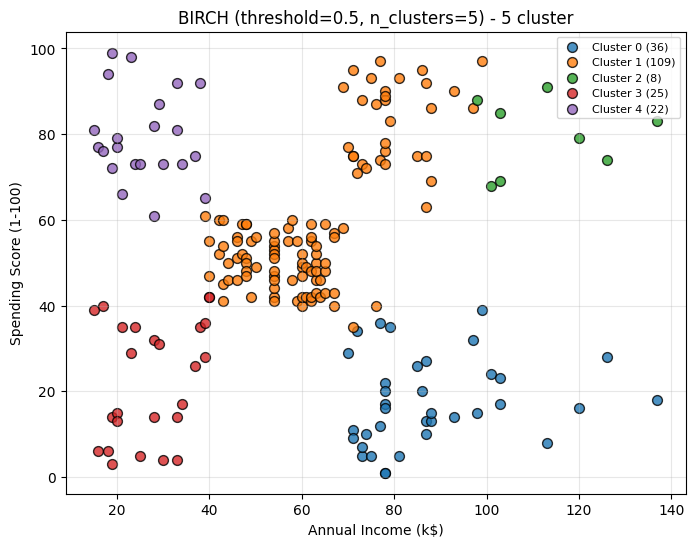

In [37]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.

fig, ax = plt.subplots(figsize=(8, 6))
plot_clusters(ax, X, labels_birch, f'BIRCH (threshold=0.5, n_clusters=5) - {n_cluster_birch} cluster')
plt.show()

In [38]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.

import warnings
warnings.filterwarnings('ignore', category=UserWarning)  # peringatan: subcluster < n_clusters

hasil_birch = []
for th in [0.3, 0.5, 0.7, 1.0]:
    m = Birch(threshold=th, n_clusters=5)
    lab = m.fit_predict(X_scaled)
    n_cl = len(np.unique(lab))
    sil = silhouette_score(X_scaled, lab) if 2 <= n_cl < len(lab) else np.nan
    hasil_birch.append({'threshold': th, 'n_clusters (param)': 5,
                        'n_subcluster (leaf)': len(m.subcluster_centers_),
                        'n_cluster akhir': n_cl, 'silhouette': sil})
df_birch_th = pd.DataFrame(hasil_birch)
print("BIRCH dengan n_clusters=5 pada berbagai threshold:")
display(df_birch_th.round(4))

# Tanpa n_clusters (None): label akhir = subcluster hasil pohon CF
hasil_birch_none = []
for th in [0.3, 0.5, 0.7, 1.0]:
    m = Birch(threshold=th, n_clusters=None)
    lab = m.fit_predict(X_scaled)
    n_cl = len(np.unique(lab))
    sil = silhouette_score(X_scaled, lab) if 2 <= n_cl < len(lab) else np.nan
    hasil_birch_none.append({'threshold': th, 'n_clusters (param)': None,
                             'n_subcluster (leaf)': len(m.subcluster_centers_),
                             'n_cluster akhir': n_cl, 'silhouette': sil})
df_birch_none = pd.DataFrame(hasil_birch_none)
print("\nBIRCH dengan n_clusters=None (tanpa clustering global tahap akhir):")
display(df_birch_none.round(4))

# Pengaruh nilai n_clusters pada threshold tetap (0.5)
hasil_birch_k = []
for k in [2, 3, 4, 5, 6, 7]:
    lab = Birch(threshold=0.5, n_clusters=k).fit_predict(X_scaled)
    hasil_birch_k.append({'threshold': 0.5, 'n_clusters (param)': k,
                          'n_cluster akhir': len(np.unique(lab)),
                          'silhouette': silhouette_score(X_scaled, lab)})
print("\nBIRCH dengan threshold=0.5 dan n_clusters bervariasi:")
display(pd.DataFrame(hasil_birch_k).round(4))

BIRCH dengan n_clusters=5 pada berbagai threshold:


,threshold,n_clusters (param),n_subcluster (leaf),n_cluster akhir,silhouette
0,0.3,5,23,5,0.4781
1,0.5,5,10,5,0.4145
2,0.7,5,6,5,0.4207
3,1.0,5,4,4,0.3886



BIRCH dengan n_clusters=None (tanpa clustering global tahap akhir):


,threshold,n_clusters (param),n_subcluster (leaf),n_cluster akhir,silhouette
0,0.3,None,23,23,0.4143
1,0.5,None,10,10,0.4774
2,0.7,None,6,6,0.4861
3,1.0,None,4,4,0.3886



BIRCH dengan threshold=0.5 dan n_clusters bervariasi:


,threshold,n_clusters (param),n_cluster akhir,silhouette
0,0.5,2,2,0.3925
1,0.5,3,3,0.3382
2,0.5,4,4,0.3518
3,0.5,5,5,0.4145
4,0.5,6,6,0.3898
5,0.5,7,7,0.5217


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

### Jawaban

**1. Pengaruh `threshold` yang diperbesar.**
`threshold` adalah radius maksimum sebuah subcluster pada pohon CF. Jika diperbesar, titik yang lebih jauh pun dapat digabung ke subcluster yang sama sehingga **jumlah subcluster (leaf) menurun** dan pohon menjadi lebih ringkas (lihat kolom `n_subcluster (leaf)` pada tabel). Akibatnya:


**2. Perbedaan BIRCH dan DBSCAN terhadap titik yang jauh dari kelompok utama.**
- **DBSCAN** secara eksplisit menandai titik yang tidak memenuhi kepadatan sebagai **noise (label -1)**, sehingga titik jauh dipisahkan dan tidak mengganggu bentuk cluster.
- **BIRCH tidak memiliki konsep noise**. Setiap titik pasti dimasukkan ke subcluster/cluster terdekat. Titik jauh dapat membentuk subcluster sendiri (jika `threshold` kecil) atau terserap ke cluster terdekat sehingga ikut menggeser pusat dan menambah sebaran cluster tersebut.

**3. Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?**
Ya. Tanpa `n_clusters` (None), label akhir adalah subcluster hasil pohon CF, sehingga jumlahnya ditentukan oleh `threshold` (dapat sangat banyak bila `threshold` kecil). Dengan `n_clusters=k`, subcluster tersebut digabung lagi melalui clustering global (agglomerative) menjadi `k` cluster. Tabel terakhir pada sel eksperimen (threshold tetap 0,5, `n_clusters` 2 sampai 7) memperlihatkan bagaimana Silhouette berubah mengikuti `k`. Nilai `k = 5` dipilih karena sesuai dengan struktur data yang terlihat pada scatter plot (lima kelompok), dan pilihan ini dapat diperiksa langsung pada tabel tersebut.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [39]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.

gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=42)
gmm.fit(X_scaled)
labels_gmm = gmm.predict(X_scaled)
print("Konvergen:", gmm.converged_, "| Jumlah iterasi EM:", gmm.n_iter_)
print("Bobot komponen (pi):", np.round(gmm.weights_, 3))
print("Rata-rata komponen (ruang scaled):")
print(np.round(gmm.means_, 3))

Konvergen: True | Jumlah iterasi EM: 5
Bobot komponen (pi): [0.413 0.197 0.104 0.166 0.121]
Rata-rata komponen (ruang scaled):
[[-0.185 -0.031]
 [ 0.98   1.235]
 [-1.353  1.162]
 [ 1.078 -1.323]
 [-1.28  -1.088]]


In [40]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.

print("Jumlah anggota tiap cluster GMM:")
print(pd.Series(labels_gmm).value_counts().sort_index())

proba = gmm.predict_proba(X_scaled)
df_proba = pd.DataFrame(proba, columns=[f'P(komp_{k})' for k in range(proba.shape[1])]).round(4)
df_proba['label'] = labels_gmm
df_proba['max_proba'] = proba.max(axis=1).round(4)
print("\nBeberapa baris probabilitas keanggotaan:")
display(df_proba.head(10))

# Titik dengan keanggotaan relatif tidak pasti (probabilitas maksimum < 0.9)
tidak_pasti = df_proba[df_proba['max_proba'] < 0.9]
print(f"\nJumlah titik dengan max probabilitas < 0.9: {len(tidak_pasti)} dari {len(df_proba)}")
display(pd.concat([X.loc[tidak_pasti.index], tidak_pasti[['label', 'max_proba']]], axis=1).head(10))
print("Rata-rata probabilitas maksimum seluruh titik:", round(proba.max(axis=1).mean(), 4))

Jumlah anggota tiap cluster GMM:
0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64

Beberapa baris probabilitas keanggotaan:


,P(komp_0),P(komp_1),P(komp_2),P(komp_3),P(komp_4),label,max_proba
0,0.0000,0.0000,0.0010,0.0000,0.9990,4,0.9990
1,0.0000,0.0002,0.9998,0.0000,0.0000,2,0.9998
2,0.0000,0.0000,0.0000,0.0002,0.9998,4,0.9998
3,0.0001,0.0002,0.9997,0.0000,0.0000,2,0.9997
4,0.0001,0.0000,0.0016,0.0000,0.9984,4,0.9984
5,0.0002,0.0002,0.9996,0.0000,0.0000,2,0.9996
6,0.0000,0.0000,0.0000,0.0003,0.9997,4,0.9997
7,0.0000,0.0003,0.9997,0.0000,0.0000,2,0.9997
8,0.0000,0.0000,0.0000,0.0004,0.9996,4,0.9996
9,0.0012,0.0002,0.9984,0.0000,0.0002,2,0.9984



Jumlah titik dengan max probabilitas < 0.9: 8 dari 200


,Annual Income (k$),Spending Score (1-100),label,max_proba
27,28,61,2,0.6746
45,39,65,0,0.8221
47,40,47,0,0.8915
48,40,42,0,0.6114
49,40,42,0,0.6114
55,43,41,0,0.7959
124,70,29,3,0.5029
160,79,35,0,0.7721


Rata-rata probabilitas maksimum seluruh titik: 0.9827


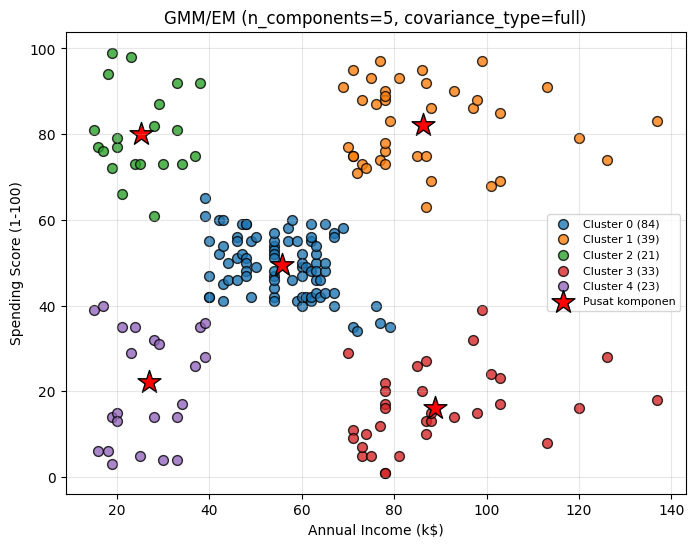

In [41]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.

fig, ax = plt.subplots(figsize=(8, 6))
plot_clusters(ax, X, labels_gmm, 'GMM/EM (n_components=5, covariance_type=full)')
# Tandai pusat komponen pada ruang fitur asli
pusat = scaler.inverse_transform(gmm.means_)
ax.scatter(pusat[:, 0], pusat[:, 1], c='red', marker='*', s=300, edgecolor='k', label='Pusat komponen')
ax.legend(fontsize=8)
plt.show()

,n_components,silhouette,BIC,AIC
0,2,0.3872,1148.4725,1112.1910
1,3,0.4302,1151.7183,1095.6469
2,4,0.4509,1079.4940,1003.6327
3,5,0.5537,1058.6523,963.0010
4,6,0.5358,1071.5668,956.1257
5,7,0.3852,1085.5904,950.3593
6,8,0.4651,1082.4804,927.4595


n_components dengan Silhouette tertinggi: 5
n_components dengan BIC terendah        : 5


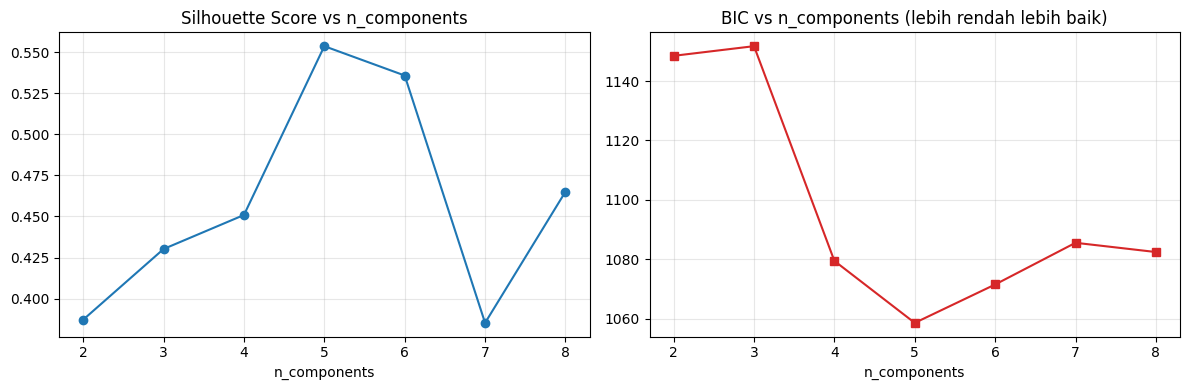

In [42]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.

hasil_gmm = []
for n in range(2, 9):
    g = GaussianMixture(n_components=n, covariance_type='full', random_state=42, n_init=5)
    g.fit(X_scaled)
    lab = g.predict(X_scaled)
    hasil_gmm.append({'n_components': n,
                      'silhouette': silhouette_score(X_scaled, lab),
                      'BIC': g.bic(X_scaled),
                      'AIC': g.aic(X_scaled)})
df_gmm_k = pd.DataFrame(hasil_gmm)
display(df_gmm_k.round(4))

n_terbaik_sil = int(df_gmm_k.loc[df_gmm_k['silhouette'].idxmax(), 'n_components'])
n_terbaik_bic = int(df_gmm_k.loc[df_gmm_k['BIC'].idxmin(), 'n_components'])
print(f"n_components dengan Silhouette tertinggi: {n_terbaik_sil}")
print(f"n_components dengan BIC terendah        : {n_terbaik_bic}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(df_gmm_k['n_components'], df_gmm_k['silhouette'], 'o-')
axes[0].set_title('Silhouette Score vs n_components'); axes[0].set_xlabel('n_components'); axes[0].grid(alpha=0.3)
axes[1].plot(df_gmm_k['n_components'], df_gmm_k['BIC'], 's-', color='tab:red')
axes[1].set_title('BIC vs n_components (lebih rendah lebih baik)'); axes[1].set_xlabel('n_components'); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

### Jawaban

**1. Arti probabilitas keanggotaan.**
Nilai pada `predict_proba` adalah **probabilitas posterior (responsibility)** `P(komponen k | x)`, yaitu seberapa besar kemungkinan suatu titik dibangkitkan oleh komponen Gaussian ke-k. Setiap baris berjumlah 1. Ini adalah *soft clustering*: label akhir hanya diambil dari probabilitas terbesar (`predict`), tetapi probabilitas menyimpan tingkat keyakinan. Titik di pusat suatu kelompok memiliki probabilitas mendekati 1, sedangkan titik di area perbatasan/tumpang tindih antar-komponen memiliki probabilitas maksimum yang lebih rendah (pada sel analisis, titik dengan probabilitas maksimum < 0,9 ditampilkan sebagai keanggotaan yang relatif tidak pasti). Informasi ini tidak dimiliki DBSCAN maupun BIRCH.

**2. Efek mengubah `n_components`.**
- Terlalu sedikit komponen: model *underfit*, beberapa kelompok yang berbeda dipaksa digabung dalam satu Gaussian sehingga BIC tinggi (buruk) dan cluster sulit diinterpretasikan.
- Terlalu banyak komponen: model *overfit*, satu kelompok alami dipecah menjadi beberapa komponen. Likelihood naik, tetapi BIC dikenai penalti jumlah parameter sehingga ikut naik, dan Silhouette turun karena cluster saling tumpang tindih.

**3. Mengapa jumlah cluster harus ditentukan sebelum training?**
GMM adalah model parametrik: jumlah komponen K menentukan banyaknya parameter yang diestimasi (bobot, rata-rata, dan kovarians setiap komponen). Algoritma EM hanya mengestimasi parameter untuk K yang sudah tetap, dan tidak memilih K itu sendiri. Karena itu K dipilih dari luar melalui percobaan beberapa nilai dan kriteria seperti BIC/AIC, Silhouette, serta visualisasi.

**4. Apakah Silhouette tertinggi sama dengan BIC terendah?**
Jawabannya dilihat dari dua baris cetakan `n_components dengan Silhouette tertinggi` dan `n_components dengan BIC terendah`. Jika keduanya menunjuk nilai yang sama, maka dua kriteria independen menguatkan pilihan tersebut. Jika berbeda, hal itu wajar karena keduanya mengukur hal berbeda: Silhouette menilai keterpisahan/kekompakan geometris cluster, sedangkan BIC menilai kecocokan model probabilistik terhadap data dengan penalti kompleksitas. Keputusan akhir sebaiknya mempertimbangkan keduanya bersama visualisasi dan makna bisnis segmen.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [43]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.

def evaluasi_clustering(X_data, labels, nama_model, noise_label=-1):
    """Hitung metrik internal. Titik noise (label -1) dikeluarkan sebelum perhitungan."""
    X_arr = np.asarray(X_data)
    labels = np.asarray(labels)
    n_noise = int(np.sum(labels == noise_label))
    mask = labels != noise_label
    X_eval, lab_eval = X_arr[mask], labels[mask]
    n_cluster = len(np.unique(lab_eval))

    hasil = {'model': nama_model, 'jumlah cluster': n_cluster,
             'jumlah noise': n_noise,
             'silhouette': np.nan, 'davies_bouldin': np.nan, 'calinski_harabasz': np.nan}
    # Metrik valid hanya bila >= 2 cluster dan jumlah cluster < jumlah titik yang dievaluasi
    if n_cluster >= 2 and n_cluster < len(lab_eval):
        hasil['silhouette'] = silhouette_score(X_eval, lab_eval)
        hasil['davies_bouldin'] = davies_bouldin_score(X_eval, lab_eval)
        hasil['calinski_harabasz'] = calinski_harabasz_score(X_eval, lab_eval)
    return hasil

In [44]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.

# DBSCAN terbaik: silhouette tertinggi dari grid dengan >= 2 cluster dan noise <= 15%
kandidat = df_dbscan_grid[(df_dbscan_grid['n_cluster'] >= 2) & (df_dbscan_grid['noise_%'] <= 15)]
if kandidat.empty:
    kandidat = df_dbscan_grid[df_dbscan_grid['n_cluster'] >= 2]
terbaik = kandidat.loc[kandidat['silhouette'].idxmax()]
eps_best, ms_best = float(terbaik['eps']), int(terbaik['min_samples'])
labels_dbscan_best = DBSCAN(eps=eps_best, min_samples=ms_best).fit_predict(X_scaled)
print(f"DBSCAN terbaik: eps={eps_best}, min_samples={ms_best}")

# BIRCH: threshold=0.5, n_clusters=5 (labels_birch);  GMM: n_components=5, full (labels_gmm)
df_evaluasi = pd.DataFrame([
    evaluasi_clustering(X_scaled, labels_dbscan_best, f'DBSCAN (eps={eps_best}, ms={ms_best})'),
    evaluasi_clustering(X_scaled, labels_birch, 'BIRCH (th=0.5, k=5)'),
    evaluasi_clustering(X_scaled, labels_gmm, 'GMM/EM (k=5, full)'),
])
# BIRCH dan GMM tidak menandai noise secara eksplisit
df_evaluasi.loc[df_evaluasi['model'].str.startswith(('BIRCH', 'GMM')), 'jumlah noise'] = 0
display(df_evaluasi.round(4))

DBSCAN terbaik: eps=0.5, min_samples=10


,model,jumlah cluster,jumlah noise,silhouette,davies_bouldin,calinski_harabasz
0,"DBSCAN (eps=0.5, ms=10)",4,21,0.5107,0.5868,156.9328
1,"BIRCH (th=0.5, k=5)",5,0,0.4145,0.6979,125.9486
2,"GMM/EM (k=5, full)",5,0,0.5537,0.5760,244.9402


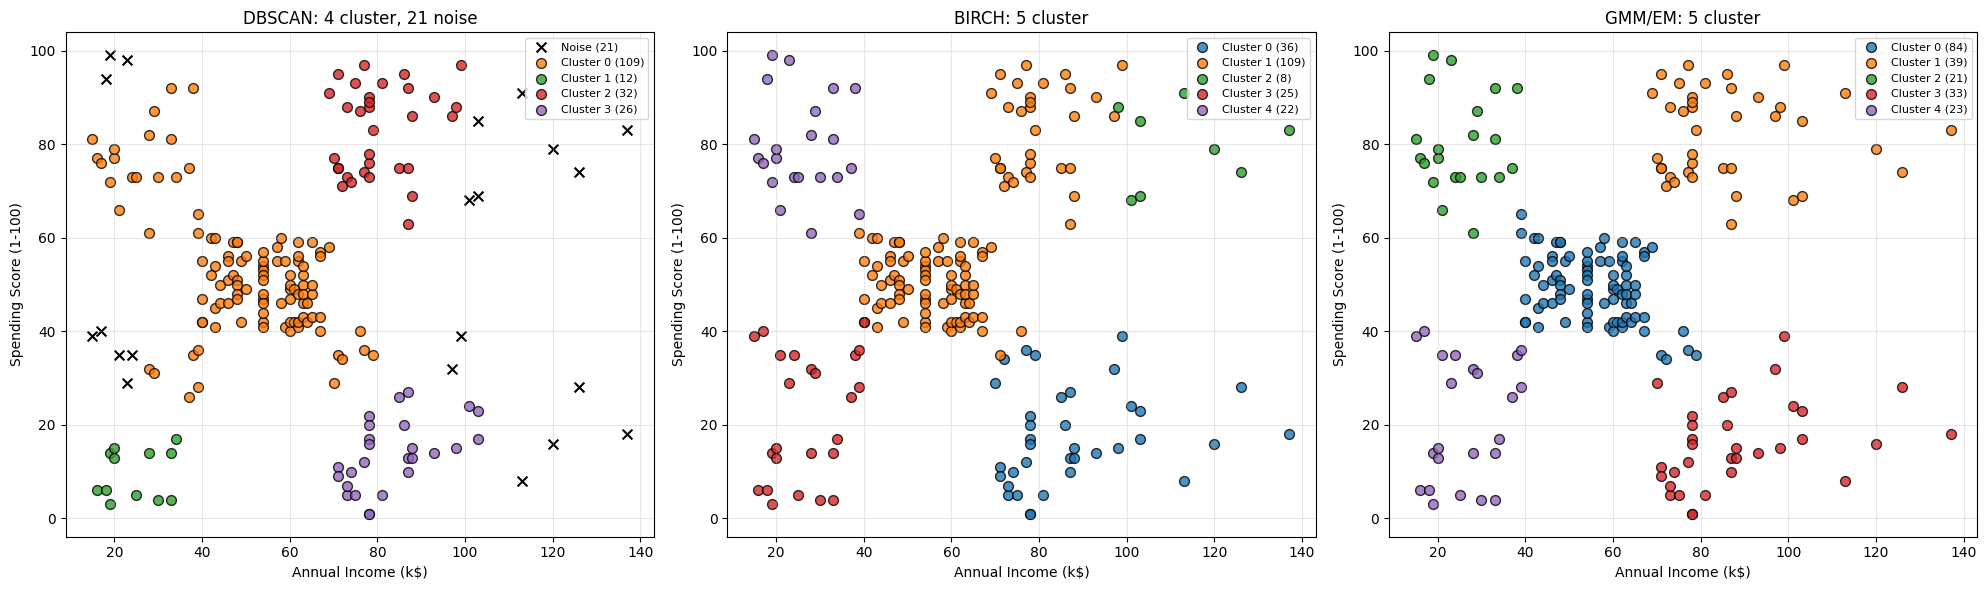

In [45]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.

n_cl_db = len(set(labels_dbscan_best)) - (1 if -1 in labels_dbscan_best else 0)
n_ns_db = int(np.sum(labels_dbscan_best == -1))

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
plot_clusters(axes[0], X, labels_dbscan_best, f'DBSCAN: {n_cl_db} cluster, {n_ns_db} noise')
plot_clusters(axes[1], X, labels_birch, f'BIRCH: {len(np.unique(labels_birch))} cluster')
plot_clusters(axes[2], X, labels_gmm, f'GMM/EM: {len(np.unique(labels_gmm))} cluster')
plt.tight_layout()
plt.show()

In [46]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.

def profil_cluster(labels, nama):
    d = X.copy()
    d['cluster'] = labels
    profil = d.groupby('cluster').agg(
        jumlah=('Annual Income (k$)', 'size'),
        median_income=('Annual Income (k$)', 'median'),
        mean_income=('Annual Income (k$)', 'mean'),
        median_spending=('Spending Score (1-100)', 'median'),
        mean_spending=('Spending Score (1-100)', 'mean'),
    ).round(2)
    print(f"=== Profil cluster {nama} ===")
    if -1 in profil.index:
        print("-- Noise (label -1) dianalisis terpisah --")
        display(profil.loc[[-1]])
        print("-- Cluster non-noise --")
        display(profil.drop(index=-1))
    else:
        display(profil)
    return profil

profil_dbscan = profil_cluster(labels_dbscan_best, 'DBSCAN (parameter terbaik)')
profil_birch = profil_cluster(labels_birch, 'BIRCH')
profil_gmm = profil_cluster(labels_gmm, 'GMM/EM')

# Interpretasi tambahan (opsional): komposisi Gender per cluster GMM (bukan input model)
print("Komposisi Gender per cluster GMM:")
display(pd.crosstab(labels_gmm, df['Gender'], normalize='index').round(3))

=== Profil cluster DBSCAN (parameter terbaik) ===
-- Noise (label -1) dianalisis terpisah --


,jumlah,median_income,mean_income,median_spending,mean_spending
cluster,,,,,
-1,21,101.0,78.81,40.0,55.19


-- Cluster non-noise --


,jumlah,median_income,mean_income,median_spending,mean_spending
cluster,,,,,
0,109,54.0,49.73,51.0,52.79
1,12,22.5,24.58,9.5,9.58
2,32,78.0,80.38,86.0,82.94
3,26,79.5,83.42,13.5,13.77


=== Profil cluster BIRCH ===


,jumlah,median_income,mean_income,median_spending,mean_spending
cluster,,,,,
0,36,83.0,87.75,16.0,17.58
1,109,62.0,62.39,55.0,59.26
2,8,108.0,112.62,81.0,79.62
3,25,28.0,27.40,26.0,22.60
4,22,24.5,25.73,77.0,79.36


=== Profil cluster GMM/EM ===


,jumlah,median_income,mean_income,median_spending,mean_spending
cluster,,,,,
0,84,55.5,55.64,49.5,49.37
1,39,79.0,86.54,83.0,82.13
2,21,24.0,25.10,77.0,80.05
3,33,86.0,88.82,15.0,16.00
4,23,25.0,26.30,17.0,20.91


Komposisi Gender per cluster GMM:


Gender,Female,Male
row_0,,
0,0.595,0.405
1,0.538,0.462
2,0.571,0.429
3,0.455,0.545
4,0.609,0.391


### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak. Jumlah cluster adalah hasil dari `eps` dan `min_samples`. | Tidak wajib: dengan `n_clusters=None` jumlah cluster mengikuti `threshold`; bila ingin jumlah tertentu, `n_clusters=k` diisi di awal. | Ya. `n_components` harus ditentukan sebelum training (dipilih dengan BIC/AIC dan Silhouette). |
| Dapat memberi label noise secara eksplisit? | Ya, titik yang tidak padat diberi label -1. | Tidak, setiap titik masuk ke suatu cluster. | Tidak secara eksplisit; hanya terlihat dari probabilitas keanggotaan yang rendah. |
| Parameter yang paling memengaruhi hasil | `eps` (paling sensitif) dan `min_samples`. | `threshold` (menentukan jumlah subcluster), `n_clusters`, dan `branching_factor`. | `n_components`, `covariance_type`, serta inisialisasi (`random_state`, `n_init`). |
| Bentuk cluster yang dapat dimodelkan | Bentuk sembarang (arbitrer), selama kepadatannya cukup. | Cenderung bulat/kompak karena berbasis radius dan centroid subcluster. | Elips (dengan `covariance_type='full'`), dengan ukuran dan orientasi berbeda antar komponen. |
| Kelebihan | Mendeteksi outlier/noise, tidak perlu menentukan jumlah cluster, mampu menangkap bentuk tidak beraturan. | Cepat dan hemat memori karena meringkas data dalam pohon CF, cocok untuk data besar dan hasil stabil bila `n_clusters` tepat. | Memberi probabilitas keanggotaan (*soft clustering*), fleksibel terhadap bentuk elips, dan dapat dipilih dengan BIC/AIC. |
| Kekurangan | Sangat sensitif terhadap `eps` dan `min_samples`, kesulitan jika kepadatan antar-cluster berbeda, dan sebagian titik tidak terklasifikasi. | Tidak mendeteksi noise, bergantung pada skala dan bentuk bulat, dan jumlah cluster akhir dapat kurang dari `n_clusters` bila `threshold` terlalu besar. | Harus menentukan K, bergantung pada inisialisasi (bisa terjebak optimum lokal), dan mengasumsikan data berdistribusi Gaussian. |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

### Jawaban

**1. Mengapa fitur perlu di-scaling?**
DBSCAN (`eps`), BIRCH (`threshold` dan penggabungan subcluster), dan GMM (estimasi rata-rata/kovarians) bergantung pada jarak atau skala fitur. Tanpa scaling, fitur dengan rentang/varians lebih besar mendominasi perhitungan jarak, dan parameter seperti `eps` sulit ditafsirkan karena satuannya berbeda (k$ dan skor 1-100). Pada notebook ini, `StandardScaler` membuat kedua fitur memiliki rata-rata 0 dan standar deviasi 1 (terlihat pada `X_scaled.describe()`), sehingga satu nilai `eps`/`threshold` memiliki arti yang sama untuk kedua sumbu. Bentuk sebaran titik pada scatter plot tidak berubah, hanya skalanya, sehingga struktur kelompok tetap terjaga.

**2. Pengaruh parameter DBSCAN.**
Tabel `df_dbscan_grid` menunjukkan bahwa menaikkan `eps` menurunkan noise dan, pada nilai besar, menggabungkan cluster hingga tersisa sangat sedikit (bahkan satu). `eps` kecil menghasilkan cluster terfragmentasi dengan noise tinggi. Menaikkan `min_samples` membuat syarat inti lebih ketat sehingga noise bertambah dan cluster kecil hilang. Kombinasi yang layak dipilih berada di rentang menengah, yaitu ketika jumlah cluster sesuai pola data (sekitar lima kelompok) dan noise tetap kecil.

**3. Pengaruh `threshold` dan `n_clusters` pada BIRCH.**
`threshold` yang lebih besar menurunkan jumlah subcluster sehingga pohon lebih ringkas dan detail halus hilang. `n_clusters` menentukan jumlah cluster akhir hasil penggabungan subcluster. Pada `n_clusters=None`, cluster akhir sama dengan subcluster sehingga bergantung penuh pada `threshold`. Pada `n_clusters=5`, hasil lebih stabil terhadap `threshold` selama subcluster yang terbentuk masih cukup banyak. Bila `threshold` terlalu besar sehingga subcluster kurang dari `n_clusters`, cluster akhir lebih sedikit dari yang diminta.

**4. Makna probabilitas GMM dan peran EM.**
Probabilitas keanggotaan adalah posterior `P(komponen k | x)` yang menyatakan seberapa mungkin titik berasal dari komponen tertentu. Dalam EM, *E-step* menghitung probabilitas ini untuk setiap titik berdasarkan parameter saat ini. *M-step* kemudian memperbarui bobot, rata-rata, dan kovarians setiap komponen dengan menggunakan probabilitas tersebut sebagai bobot titik (titik dengan probabilitas tinggi berkontribusi lebih besar). Kedua langkah diulang sampai log-likelihood konvergen (`gmm.converged_` dan `gmm.n_iter_` pada output).

**5. Model yang paling mudah diinterpretasikan.**
Pada dataset ini, **BIRCH dan GMM dengan 5 cluster** paling mudah diinterpretasikan karena seluruh pelanggan terpetakan ke lima segmen yang masing-masing memiliki profil pendapatan dan spending yang jelas pada tabel profil. GMM memberi nilai tambah berupa probabilitas keanggotaan serta rata-rata dan kovarians tiap komponen. DBSCAN juga mudah dibaca secara visual dan unggul dalam mengisolasi titik yang tidak jelas, tetapi hasilnya bergantung pada pemilihan `eps`/`min_samples`, dan titik noise perlu dianalisis terpisah sehingga tidak semua pelanggan memiliki segmen.

**6. Apakah metrik menunjuk algoritma terbaik yang sama?**
Bandingkan ketiga baris pada `df_evaluasi` (Silhouette tinggi, Davies-Bouldin rendah, dan Calinski-Harabasz tinggi lebih baik). Ketiga metrik tidak selalu menunjuk model yang sama, dan perbedaan itu wajar karena:
- Metrik DBSCAN dihitung hanya pada titik non-noise, sehingga yang dinilai adalah subset yang lebih padat dan mudah dipisahkan. Skornya cenderung tampak lebih tinggi dan tidak sebanding secara langsung dengan model yang mencakup semua titik.
- Silhouette, Davies-Bouldin, dan Calinski-Harabasz mengasumsikan cluster kompak dan cembung, sehingga lebih menguntungkan model yang menghasilkan cluster bulat dan dapat merugikan GMM, yang membentuk komponen elips dengan area tumpang tindih.
- Setiap metrik mengukur aspek berbeda (rasio jarak antar-cluster dan dalam-cluster, rasio sebaran, atau kemiripan antar-cluster), dan metrik internal tidak mengukur kebermaknaan bisnis segmen.

Karena itu, pemilihan model perlu menggabungkan metrik, visualisasi, dan interpretabilitas.

**7. Karakteristik cluster (berdasarkan median pendapatan dan spending pada tabel profil).**
Pada BIRCH dan GMM terbentuk lima segmen dengan pola umum berikut (nilai pastinya dapat dilihat pada tabel profil):
- **Hemat/berhati-hati (pendapatan rendah, spending rendah)**: median pendapatan sekitar 25 k$ dan spending sekitar 15-20.
- **Muda boros / impulsif (pendapatan rendah, spending tinggi)**: median pendapatan sekitar 25 k$ dengan spending sekitar 80.
- **Pelanggan umum/moderat (pendapatan sedang, spending sedang)**: median pendapatan sekitar 55 k$ dan spending sekitar 50. Ini cluster terbesar.
- **Berpendapatan tinggi tetapi pelit (pendapatan tinggi, spending rendah)**: median pendapatan sekitar 85-90 k$ dan spending sekitar 15-20, yaitu segmen potensial untuk strategi promosi.
- **Pelanggan premium/loyal (pendapatan tinggi, spending tinggi)**: median pendapatan sekitar 85 k$ dan spending sekitar 80-85, yaitu segmen paling bernilai.

Pada DBSCAN, kelima segmen tersebut juga terlihat, ditambah label -1 (noise) yang berisi titik di perbatasan atau area renggang antar-segmen, dan profil noise sebaiknya dibaca terpisah (biasanya berpendapatan menengah dan tidak mewakili segmen tertentu).

**8. Keterbatasan dua fitur dan dataset kecil.**
- Hanya dua fitur (pendapatan dan spending score) mengabaikan informasi lain seperti `Age`, `Gender`, frekuensi kunjungan, kategori produk, dan riwayat pembelian, sehingga segmentasi bersifat dangkal.
- Dengan hanya 200 pelanggan, estimasi parameter (terutama kovarians GMM dan kepadatan DBSCAN) kurang stabil, dan cluster kecil hanya berisi sekitar 20-40 titik, sehingga hasil sensitif terhadap data tertentu dan pemilihan parameter.
- Data kemungkinan bersifat sintetis/terstruktur sehingga kelompoknya jauh lebih jelas daripada data pelanggan nyata. Hasil ini belum tentu dapat digeneralisasi ke data yang lebih besar, berdimensi tinggi, dan lebih berisik.
- Metrik internal tidak membuktikan bahwa segmen berguna secara bisnis, dan perlu validasi tambahan (misalnya, uji stabilitas dengan berbagai `random_state` atau data baru).

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

### Jawaban

**1. Algoritma yang paling berguna untuk dataset ini.**
Untuk tujuan segmentasi pelanggan, **GMM (EM) dan BIRCH dengan 5 cluster** memberikan hasil paling berguna karena setiap pelanggan masuk ke satu dari lima segmen yang jelas dan mudah dijelaskan secara bisnis (lihat tabel profil dan scatter plot perbandingan). GMM sedikit lebih unggul secara interpretatif karena menyediakan probabilitas keanggotaan sehingga pelanggan di perbatasan segmen dapat diidentifikasi. DBSCAN berguna sebagai pembanding dan untuk menyaring titik yang tidak jelas masuk segmen mana, tetapi karena sebagian pelanggan menjadi noise dan hasilnya sensitif terhadap `eps`, ia kurang praktis sebagai satu-satunya metode segmentasi. Perbandingan angka metrik yang sebenarnya dapat dilihat pada tabel `df_evaluasi`.

**2. Parameter yang dipilih dan alasannya.**
- **DBSCAN**: percobaan awal `eps=0.3`, `min_samples=5` pada data ter-scaling, lalu parameter akhir dipilih dari grid berdasarkan Silhouette tertinggi dengan batas noise maksimal 15% (tertera pada cetakan `DBSCAN terbaik`). Batasan noise diberikan agar Silhouette tinggi tidak berasal dari hasil yang membuang terlalu banyak titik.
- **BIRCH**: `threshold=0.5` dan `n_clusters=5`. Nilai `n_clusters=5` sesuai dengan pola kelompok pada scatter plot, dan `threshold=0.5` cukup kecil untuk menyisakan subcluster yang memadai tanpa memecah kelompok menjadi terlalu banyak cluster kecil.
- **GMM**: `n_components=5`, `covariance_type='full'`, `random_state=42`. Jumlah komponen 5 dipilih berdasarkan struktur yang terlihat pada scatter plot dan diperiksa dengan perbandingan Silhouette dan BIC pada rentang 2 sampai 8 (tabel `df_gmm_k`). Kovarians `full` dipilih agar setiap komponen dapat berbentuk elips dengan orientasi sendiri.

**3. Perbedaan utama ketiga algoritma.**
- **DBSCAN**: berbasis kepadatan, tidak perlu menentukan jumlah cluster, dapat memberi label noise, dan dapat menangkap bentuk sembarang, tetapi sangat sensitif terhadap `eps`/`min_samples` dan tidak menetapkan semua titik ke cluster.
- **BIRCH**: berbasis pohon CF yang meringkas data, cepat dan efisien untuk data besar. Ia tidak mengenali noise dan cenderung membentuk cluster bulat, dan hasil akhirnya sangat dipengaruhi `threshold` serta `n_clusters`.
- **EM/GMM**: berbasis model probabilistik, memberi soft assignment dan bentuk cluster elips, dan jumlah komponen dapat dipilih secara terukur dengan BIC/AIC, tetapi mengasumsikan distribusi Gaussian dan bergantung pada inisialisasi serta pemilihan K.

**4. Eksperimen lanjutan yang dapat dilakukan.**
- Menambahkan fitur lain seperti `Age` (dan `Gender` yang sudah di-encode) lalu membandingkan hasil clustering 3 fitur atau lebih, dengan visualisasi PCA atau t-SNE.
- Membandingkan dengan K-Means, Agglomerative Clustering, atau HDBSCAN (yang lebih tahan terhadap kepadatan yang berbeda).
- Menguji `covariance_type` lain pada GMM (`tied`, `diag`, `spherical`) dan menggunakan `n_init` lebih besar untuk menguji kestabilan terhadap inisialisasi.
- Menggunakan grid search/k-distance plot untuk memilih `eps` DBSCAN secara lebih sistematis, serta menguji stabilitas hasil dengan resampling atau berbagai `random_state`.
- Mengevaluasi segmen dengan validasi eksternal/bisnis (misalnya respons terhadap promosi) agar kualitas cluster tidak hanya dinilai dari metrik internal.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)